# Marine microplastic concentration prediction

Arnab Chakraborty (230102016), Gourab Adhikari (230102003)

This notebook predicts microplastic concentration in sea water (pieces/m3) from where, when and how a
sample was taken, using the NOAA NCEI Marine Microplastics database. The headline question is whether a
model generalises to a study it has never seen, so every model is scored under three splits:

- **Random** 5-fold CV. Near-duplicate samples from one cruise land on both sides of the split.
- **Grouped** 5-fold CV with the study as the group. No study appears in both train and test.

- **Chronological** holdout. Train on samples before 2015, test on 2015 onwards.

A "study" is a set of records linked by publication (DOI) or NCEI accession. Most studies are one
publication in one accession. One publication was archived as two accessions with overlapping cruises,
and one accession holds a published Oceaneye survey plus its later unpublished data, so grouping by
either field alone would split a study across train and test.

In [1]:
import json
import subprocess
from collections.abc import Callable
from pathlib import Path
from tempfile import TemporaryDirectory

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import h5py
import shap
import shapefile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, KFold
from sklearn.neighbors import BallTree, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

DATA = Path("data/noaa_microplastics.csv")
GAMM_SCRIPT = Path("gamm.R")
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
SEED = 0

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_MUTED,
    "axes.labelcolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "font.size": 10,
})
pd.set_option("display.precision", 3)

## 1. The raw data

The NCEI export has 29,076 records and 35 columns, with samples from 1972 to 2026. Column names are
shortened below. Fields that are mostly missing (bottom depth, sediment depth, transect number and so
on) are not carried forward.

In [2]:
raw = pd.read_csv(DATA, low_memory=False)
data = raw.rename(columns={
    "Sample Date": "date",
    "Latitude (degree)": "lat",
    "Longitude (degree)": "lon",
    "Ocean": "ocean",
    "Marine Setting": "medium",
    "Water Sample Depth (m)": "depth",
    "Sampling Method": "method",
    "Mesh Size (mm)": "mesh",
    "Microplastics Measurement": "conc",
    "Unit": "unit",
    "NCEI Accession Number": "accession",
    "DOI": "doi",
    "Organization": "organization",
})[["date", "lat", "lon", "ocean", "medium", "depth", "method", "mesh", "conc", "unit", "accession", "doi", "organization"]]
data["date"] = pd.to_datetime(data.date, format="%m/%d/%Y %I:%M:%S %p")

print(f"{len(raw):,} records, {data.accession.nunique()} accessions, {data.organization.nunique()} organisations")
raw.isna().mean().sort_values(ascending=False).rename("missing").to_frame().T

29,076 records, 96 accessions, 68 organisations


,Transect Number,Ocean Bottom Depth (m),Sampling Point on Beach,Sediment Sample Depth (m),Subregion,State,Volunteers Number,Standardized Nurdle Amount,Collecting Time (min),Beach Location,...,Concentration Class Range,Unit,Long Reference,Short Reference,Concentration Class,DOI,NCEI Accession Number,Organization,ObjectId,NCEI Accession Link
missing,0.99,0.989,0.981,0.977,0.937,0.647,0.635,0.635,0.635,0.623,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


The concentration column mixes incompatible units: pieces/m3 for water and beach sand, pieces/kg for
sediment, and pellets per 10 minutes of searching for the Nurdle Patrol records, which have no value in
this column at all. They cannot be converted into each other, so only the water records reported in
pieces/m3 are modelled.

In [3]:
data.groupby(["medium", "unit"], dropna=False).agg(
    records=("conc", "size"),
    with_value=("conc", "count"),
    accessions=("accession", "nunique"),
    median=("conc", "median"),
)

,,records,with_value,accessions,median
medium,unit,,,,
Beach,pieces/m3,893,893,13,1280.000
Nurdle Patrol,pieces/10 mins,10615,0,1,NaN
Ocean sediment,pieces kg-1 d.w.,580,580,18,52.727
Ocean water,pieces/m3,16988,16988,73,0.011


893 beach records are reported in pieces/m3 too, but they measure a volume of sand, not sea water.
They are dropped, which leaves **ocean water in pieces/m3** as the modelling set.

Two studies are stored on the wrong scale. The database holds 1,389 of the one-litre grab samples from
Barrows et al. (2018), who report a mean of 11.8 particles per litre, or 11,800 pieces/m3. The database
mean for those samples is 0.0128 pieces/m3, so the litre-to-m3 conversion divided by 1,000 instead of
multiplying. The Niskin bottle samples from Dehm et al. (2020) have the same error: the paper reports
1.6 to 2.0 pieces per litre, the database mean is 0.0018 pieces/m3. Both are multiplied by 10^6 below.

The other litre-scale study, McEachern et al. (2019), matches its paper (mean 0.94 per litre, maximum
7.0). The 33 bongo net samples from Arteaga et al. (2024) have a median of 2,860 pieces/m3, far above
other nets, but the paper's abstract mixes units and the full text is paywalled, so they are left as
they are.

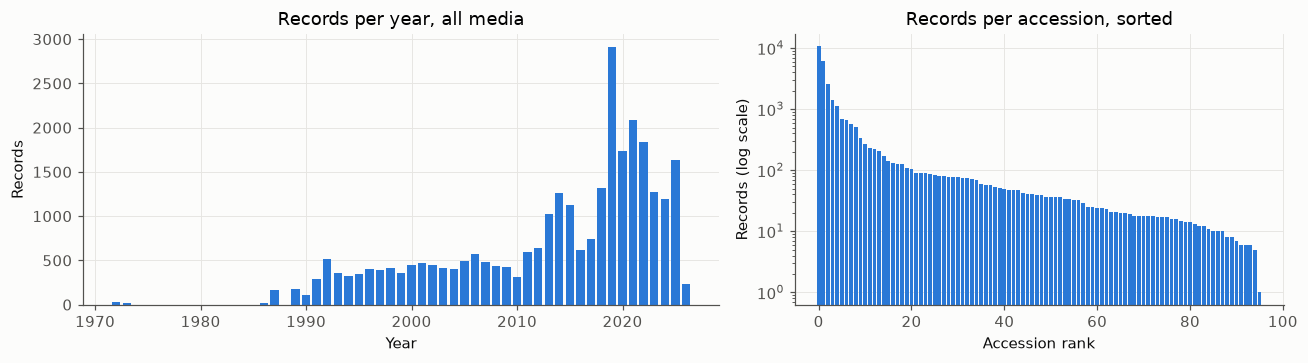

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
per_year = data.groupby(data.date.dt.year).size()
axes[0].bar(per_year.index, per_year.values, color=BLUE, width=0.8)
axes[0].set(title="Records per year, all media", xlabel="Year", ylabel="Records")
per_accession = data.accession.value_counts().to_numpy()
axes[1].bar(np.arange(len(per_accession)), per_accession, color=BLUE, width=0.8)
axes[1].set(title="Records per accession, sorted", xlabel="Accession rank", ylabel="Records (log scale)", yscale="log")
fig.tight_layout()

A handful of studies dominate. The largest accession (Sea Education Association, 1986 to 2008) holds
6,135 records on its own.

## 2. The modelling set

In [5]:
METHOD_FAMILY = {
    "neuston net": "surface net",
    "manta net": "surface net",
    "plankton net": "surface net",
    "avani net": "surface net",
    "bongo net": "surface net",
    "pump": "pump",
    "intake seawater pump": "pump",
    "surface water intake": "pump",
}
def linked_groups(a: pd.Series, b: pd.Series) -> pd.Series:
    """Labels rows linked through shared values of a or b, directly or via a chain, with one group."""
    group = a.astype(str)
    while not (merged := group.groupby(b).transform("min").groupby(a).transform("min")).equals(group):
        group = merged
    return group


UNIT_FIXES = {  # see section 1
    "https://doi.org/10.1016/j.envpol.2018.02.062": 1e6,  # Barrows et al. 2018
    "https://doi.org/10.1016/j.marpolbul.2020.111239": 1e6,  # Dehm et al. 2020
}
C = 1e-3  # offset for the log target, roughly the smallest non-zero concentration (6.8e-4)

water = data[(data.medium == "Ocean water") & (data.unit == "pieces/m3")].reset_index(drop=True)
water["conc"] *= water.doi.map(UNIT_FIXES).fillna(1)
method = water.method.str.lower().str.replace("-", " ")
family = method.map(METHOD_FAMILY).fillna("bulk water")
month = water.date.dt.month
df = water.assign(
    method=method,
    method_family=family,
    fam_pump=(family == "pump").astype(float),
    fam_bulk=(family == "bulk water").astype(float),
    year=water.date.dt.year,
    month_sin=np.sin(2 * np.pi * month / 12),
    month_cos=np.cos(2 * np.pi * month / 12),
    log_mesh=np.log10(water.mesh),
    log_depth=np.log1p(water.depth),
    study=linked_groups(water.doi, water.accession),
    y=np.log10(water.conc + C),
)
print(f"{len(df):,} records, {df.accession.nunique()} accessions, {df.doi.nunique()} publications, {df.study.nunique()} studies, {df.organization.nunique()} organisations")
df.groupby(["method_family", "method"]).agg(
    records=("y", "size"), accessions=("accession", "nunique"), median_conc=("conc", "median")
).sort_values(["method_family", "records"], ascending=[True, False])

16,988 records, 73 accessions, 73 publications, 72 studies, 52 organisations


records  accessions  median_conc
method_family method                                                   
bulk water    grab sample                 1389           1     5000.000
              van dorn sampler             181           1        0.000
              niskin bottle                 81           1     1300.000
              stainless steel bucket        80           2      860.000
              aluminum bucket               57           1     1710.000
              ctd rosette sampler           48           1       21.000
              steel bucket                  43           3      430.000
              stainless steel sampler       23           1     2600.000
              glass jar                      1           1        0.018
pump          pump                         563           1        6.000
              intake seawater pump         284           4        1.000
              surface water intake           5           1     5015.000
surface net   neuston net                10720          17        0.004
              manta net                   3204          36        0.363
              plankton net                 240           8        0.431
              avani net                     36           1        0.063
              bongo net                     33           1     2860.000

Sampling methods are grouped into three families. Surface nets are towed at the surface and catch
particles larger than the mesh (mostly 0.33 mm). Bulk water samples (bottles, buckets, grab samples)
are filtered through much finer meshes and report concentrations orders of magnitude higher. Pumps sit
in between. CatBoost also gets the raw method name to check whether the grouping loses anything.

Text(0.5, 1.0, 'Observed concentration, ocean water samples')

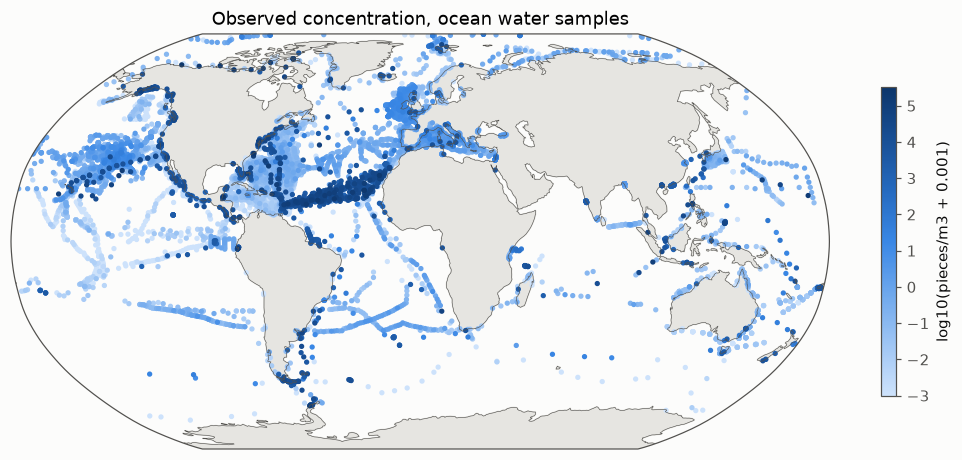

In [6]:
fig = plt.figure(figsize=(12, 5.2))
ax = fig.add_subplot(projection=ccrs.Robinson())
ax.set_global()
ax.add_feature(cfeature.LAND, color="#e6e5e1")
ax.coastlines(linewidth=0.4, color=INK_MUTED)
order = df.sort_values("y")
points = ax.scatter(order.lon, order.lat, c=order.y, cmap=SEQUENTIAL, s=6, transform=ccrs.PlateCarree())
fig.colorbar(points, ax=ax, shrink=0.7, label="log10(pieces/m3 + 0.001)")
ax.set_title("Observed concentration, ocean water samples")

Sampling is concentrated in the North Atlantic and North Pacific. The Southern Ocean has 27 records and
the Indian Ocean 528, so anything the models say about those basins is an extrapolation.

### 2.1 Choosing the target transform

The synopsis proposed `log1p`. That turns out to be a poor fit for this data. 64% of the concentrations
are below 0.1 pieces/m3, and for small x, `log1p(x) ≈ x`, so `log1p` leaves the bulk of the
distribution untransformed. A sample at 0.001 and one at 0.05 differ by a factor of 50 but end up
0.05 apart, while the few samples above 1,000 still dominate the variance.

`log10(conc + 0.001)` spreads the data over its real range. The offset 0.001 pieces/m3 is close to the
smallest non-zero value, so it acts as a detection floor. Zeros map to -3. Errors on this scale read
directly as orders of magnitude, which is the natural unit for a quantity spanning eight of them.

share below 0.1 pieces/m3: 64%, share of zeros: 29%


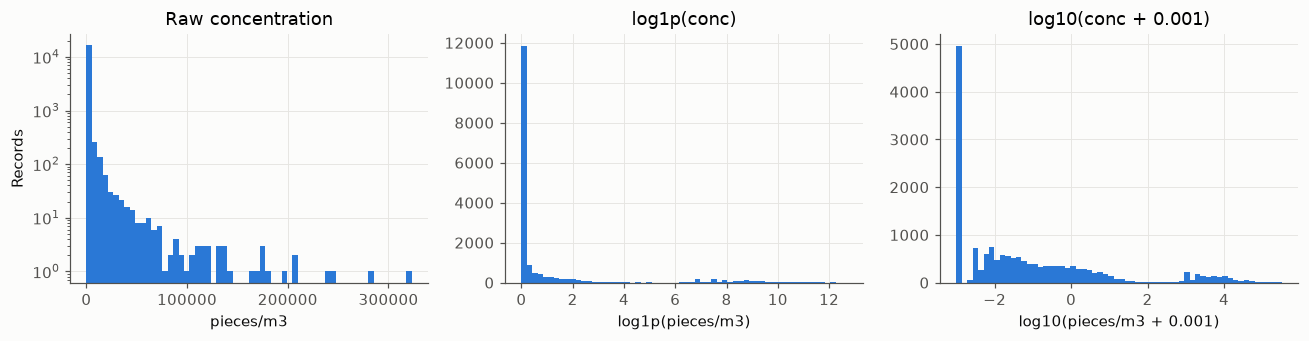

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].hist(df.conc, bins=60, color=BLUE)
axes[0].set(title="Raw concentration", xlabel="pieces/m3", ylabel="Records", yscale="log")
axes[1].hist(np.log1p(df.conc), bins=60, color=BLUE)
axes[1].set(title="log1p(conc)", xlabel="log1p(pieces/m3)")
axes[2].hist(df.y, bins=60, color=BLUE)
axes[2].set(title="log10(conc + 0.001)", xlabel="log10(pieces/m3 + 0.001)")
fig.tight_layout()
print(f"share below 0.1 pieces/m3: {(df.conc < 0.1).mean():.0%}, share of zeros: {(df.conc == 0).mean():.0%}")

### 2.2 How much does study identity explain?

Before fitting anything, it helps to know how much of the variance is between studies rather than
within them. An intercept-only mixed model gives the intraclass correlation (ICC): the share of
target variance that sits in the study-level random intercept. The ICC describes how clustered the data
is. It does not say why.

ICC for study: 0.63


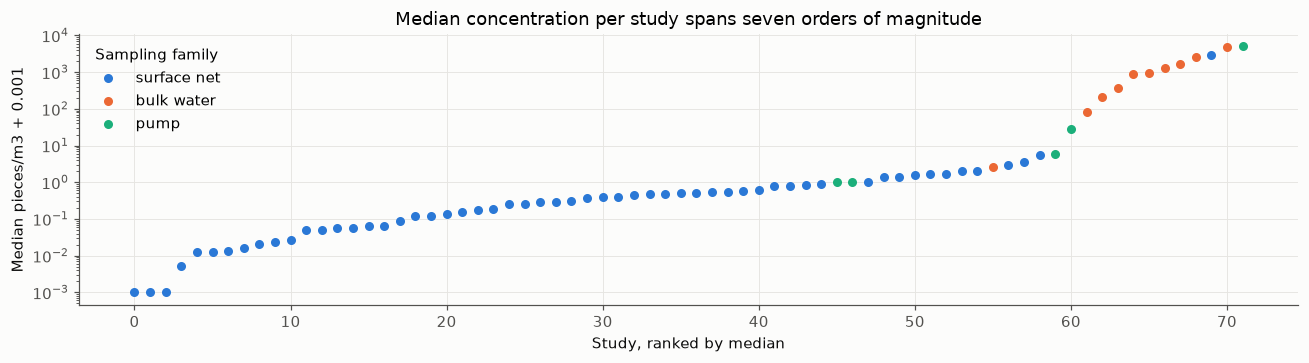

In [8]:
null_mixed = smf.mixedlm("y ~ 1", df, groups=df.study).fit()
between = float(null_mixed.cov_re.iloc[0, 0])
icc = between / (between + null_mixed.scale)
print(f"ICC for study: {icc:.2f}")

study_medians = df.groupby("study").agg(median=("conc", "median"), method=("method_family", "first"), n=("y", "size"))
fig, ax = plt.subplots(figsize=(12, 3.4))
families = {"surface net": BLUE, "bulk water": ORANGE, "pump": AQUA}
ranked = study_medians.sort_values("median").reset_index()
for name, color in families.items():
    part = ranked[ranked.method == name]
    ax.scatter(part.index, part["median"] + C, color=color, s=24, label=name)
ax.set(yscale="log", xlabel="Study, ranked by median", ylabel="Median pieces/m3 + 0.001",
       title="Median concentration per study spans seven orders of magnitude")
ax.legend(title="Sampling family")
fig.tight_layout()

Most of the variance sits between studies. Some of that is physics (fine-mesh bulk samples catch small
fibres that 0.33 mm nets miss), some is where and when each study sampled, and some is study-level
practice that no field in the dataset records. The data cannot separate these cleanly, because each study
tends to use one protocol in one region over a few years.

## 3. Features and validation

Features: latitude, longitude, year, month (as sine and cosine so December sits next to January), sampling
family, log mesh size and log water depth. Medium is constant after filtering, so it is not a feature.
Missing depth (0.3% of rows) is imputed with the training-fold median.

In [9]:
NUMERIC = ["lat", "lon", "year", "month_sin", "month_cos", "log_mesh", "log_depth"]
CATEGORICAL = ["method_family"]
FEATURES = NUMERIC + CATEGORICAL
CUTOFF = 2015

SPLITS = {
    "random": list(KFold(5, shuffle=True, random_state=SEED).split(df)),
    "grouped": list(GroupKFold(5).split(df, groups=df.study)),
    "chrono": [(np.flatnonzero(df.year < CUTOFF), np.flatnonzero(df.year >= CUTOFF))],
}
for scheme, folds in SPLITS.items():
    sizes = [len(test) for _, test in folds]
    print(f"{scheme:>8}: {len(folds)} fold(s), test sizes {sizes}")
pre, post = df[df.year < CUTOFF], df[df.year >= CUTOFF]
seen = post.study.isin(pre.study)
print(f"chrono: {pre.study.nunique()} studies before {CUTOFF}, {post.study.nunique()} after, "
      f"{post[seen].study.nunique()} in both. {seen.sum():,} of {len(post):,} test rows come from studies seen in training")

  random: 5 fold(s), test sizes [3398, 3398, 3398, 3397, 3397]
 grouped: 5 fold(s), test sizes [6135, 2714, 2712, 2714, 2713]
  chrono: 1 fold(s), test sizes [4638]
chrono: 25 studies before 2015, 54 after, 7 in both. 2,155 of 4,638 test rows come from studies seen in training


Grouped folds are uneven because one study holds 36% of the rows. The chronological test set mixes two
things: most of its studies are new, but a large share of its rows come from long-running studies that
also appear before 2015. Its results are therefore also broken down by seen and unseen studies.

Every model is a function that takes a training frame and returns a predictor. Each model gets the
same folds.

In [10]:
Predictor = Callable[[pd.DataFrame], np.ndarray]
Model = Callable[[pd.DataFrame], Predictor]


def preprocessor(features: list[str] = FEATURES) -> ColumnTransformer:
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), [f for f in features if f not in CATEGORICAL]),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), [f for f in features if f in CATEGORICAL]),
    ])


def clip_to_range(train: pd.DataFrame) -> Callable[[pd.DataFrame], pd.DataFrame]:
    """Clips numeric features to the training range, so models that extrapolate (linear, splines) stay flat
    outside it. Trees already behave this way."""
    low, high = train[NUMERIC].min(), train[NUMERIC].max()
    return lambda frame: frame.assign(**{c: frame[c].clip(low[c], high[c]) for c in NUMERIC})


def sklearn_model(estimator, features: list[str] = FEATURES) -> Model:
    def fit(train: pd.DataFrame) -> Predictor:
        clip = clip_to_range(train)
        pipe = make_pipeline(preprocessor(features), clone(estimator)).fit(train[features], train.y)
        return lambda test: pipe.predict(clip(test)[features])
    return fit


def fit_study_mean(train: pd.DataFrame) -> Predictor:
    """Predicts the training mean of the sample's own study. Falls back to the global mean for unseen studies."""
    means = train.groupby("study").y.mean()
    return lambda test: test.study.map(means).fillna(train.y.mean()).to_numpy()


def fit_knn(train: pd.DataFrame) -> Predictor:
    """Inverse-distance weighted average of the 15 nearest samples on the sphere. Location only."""
    knn = KNeighborsRegressor(n_neighbors=15, weights="distance", metric="haversine", algorithm="ball_tree")
    knn.fit(np.radians(train[["lat", "lon"]]), train.y)
    return lambda test: knn.predict(np.radians(test[["lat", "lon"]]))


GAMM_COLUMNS = NUMERIC + ["fam_pump", "fam_bulk", "study"]


def fit_gamm(train: pd.DataFrame) -> Predictor:
    """GAMM fitted by R's mgcv through `gamm.R`. Studies seen in training get their random effect added;
    unseen studies get the population-level prediction."""
    medians = train[NUMERIC].median()
    clip = clip_to_range(train)

    def prepare(frame: pd.DataFrame) -> pd.DataFrame:
        return clip(frame.fillna({c: medians[c] for c in NUMERIC}))[GAMM_COLUMNS]

    def predict(test: pd.DataFrame) -> np.ndarray:
        with TemporaryDirectory() as tmp:
            train_csv, test_csv, out_csv = (Path(tmp) / name for name in ("train.csv", "test.csv", "pred.csv"))
            prepare(train).assign(y=train.y).to_csv(train_csv, index=False)
            prepare(test).to_csv(test_csv, index=False)
            run = subprocess.run(["Rscript", GAMM_SCRIPT, train_csv, test_csv, out_csv], capture_output=True, text=True)
            if run.returncode:
                raise RuntimeError(run.stderr)
            return pd.read_csv(out_csv).pred.to_numpy()
    return predict


BOOSTER_DEFAULTS = dict(n_estimators=500, learning_rate=0.05, random_state=SEED, n_jobs=4)
CATBOOST_FEATURES = FEATURES + ["method"]


def train_catboost(train: pd.DataFrame, features: list[str] = CATBOOST_FEATURES, **params) -> CatBoostRegressor:
    cats = train[features].select_dtypes(exclude="number").columns.tolist()
    model = CatBoostRegressor(
        **{"iterations": 500, "learning_rate": 0.05, "random_seed": SEED, "thread_count": 4, "verbose": 0} | params
    )
    return model.fit(train[features], train.y, cat_features=cats)


def fit_catboost(train: pd.DataFrame, features: list[str] = CATBOOST_FEATURES, **params) -> Predictor:
    model = train_catboost(train, features, **params)
    return lambda test: model.predict(test[features])


def fit_hurdle(train: pd.DataFrame) -> Predictor:
    """Two-part XGBoost: P(conc > 0) times the positive-part regression, plus P(conc = 0) times the zero level."""
    positive = train[train.conc > 0]
    classifier = make_pipeline(preprocessor(), XGBClassifier(**BOOSTER_DEFAULTS)).fit(train[FEATURES], train.conc > 0)
    regressor = make_pipeline(preprocessor(), XGBRegressor(**BOOSTER_DEFAULTS)).fit(positive[FEATURES], positive.y)

    def predict(test: pd.DataFrame) -> np.ndarray:
        p = classifier.predict_proba(test[FEATURES])[:, 1]
        return p * regressor.predict(test[FEATURES]) + (1 - p) * np.log10(C)
    return predict


MODELS: dict[str, Model] = {
    "Study mean only": fit_study_mean,
    "Linear regression": sklearn_model(LinearRegression()),
    "GAMM (mgcv)": fit_gamm,
    "Spatial kNN": fit_knn,
    "Random forest": sklearn_model(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=4, random_state=SEED)),
    "XGBoost": sklearn_model(XGBRegressor(**BOOSTER_DEFAULTS, max_depth=6)),
    "LightGBM": sklearn_model(LGBMRegressor(**BOOSTER_DEFAULTS, verbose=-1)),
    "CatBoost": fit_catboost,
    "XGBoost hurdle": fit_hurdle,
}

"Study mean only" is a reference point, not a candidate. It knows nothing except which study a sample
came from. Under random CV it shows how far study identity alone gets you. Under grouped CV it collapses
to the global mean. The spatial kNN baseline asks whether a model beats "average the nearest samples".

### 3.1 Metrics

The primary metrics are on the log10 scale: R², MAE and RMSE, plus the share of predictions within one
log10 unit of the truth. Because of the 0.001 offset, "within one log unit" is measured on
`conc + 0.001`, so a true zero and a prediction of 0.009 count as a match.

"Study MAE" averages the MAE of each study, so a small study counts as much as the 6,000-row one. That is
the closer match to "how wrong will the model be on the next study".

Raw-scale MAE and RMSE use `10**pred - 0.001`. A back-transformed log prediction is not an estimate of the
raw mean, and raw RMSE is dominated by a handful of samples above 1,000 pieces/m3, so raw metrics are
secondary.

In [11]:
def metrics(y: np.ndarray, pred: np.ndarray) -> dict[str, float]:
    err = pred - y
    raw_err = np.clip(10**pred - C, 0, None) - (10**y - C)
    return {
        "R2": 1 - np.sum(err**2) / np.sum((y - y.mean()) ** 2),
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err**2)),
        "within 1 log": np.mean(np.abs(err) <= 1),
        "raw MAE": np.mean(np.abs(raw_err)),
        "raw RMSE": np.sqrt(np.mean(raw_err**2)),
    }


def score(pred: pd.Series) -> dict[str, float]:
    """Metrics for a series of out-of-fold predictions indexed like df. NaN entries are skipped."""
    pred = pred.dropna()
    y = df.y.loc[pred.index]
    study_mae = (pred - y).abs().groupby(df.study.loc[pred.index]).mean().mean()
    return metrics(y.to_numpy(), pred.to_numpy()) | {"study MAE": study_mae}


Folds = list[tuple[np.ndarray, np.ndarray]]


def out_of_fold(model: Model, folds: Folds) -> pd.Series:
    """Out-of-fold predictions indexed like df. Rows in no test fold stay NaN."""
    pred = pd.Series(np.nan, index=df.index)
    for train_idx, test_idx in folds:
        pred.iloc[test_idx] = model(df.iloc[train_idx])(df.iloc[test_idx])
    return pred


SHOWN = ["R2", "MAE", "study MAE", "within 1 log"]

## 4. Model comparison

In [12]:
predictions = {(name, scheme): out_of_fold(model, SPLITS[scheme]) for name, model in MODELS.items() for scheme in SPLITS}
results = pd.DataFrame(
    [{"model": name, "scheme": scheme} | score(pred) for (name, scheme), pred in predictions.items()]
).set_index(["model", "scheme"])
results.to_csv(ARTIFACTS / "model_comparison.csv")
results[SHOWN].unstack("scheme").reindex(MODELS).swaplevel(axis=1)[["random", "grouped", "chrono"]]

scheme            random                               grouped         \
                      R2    MAE study MAE within 1 log      R2    MAE   
model                                                                   
Study mean only    0.664  0.772     0.571        0.793  -0.283  1.792   
Linear regression  0.545  0.972     1.063        0.613   0.407  1.158   
GAMM (mgcv)        0.715  0.680     0.566        0.828  -1.099  2.378   
Spatial kNN        0.560  0.751     0.672        0.792  -1.946  2.787   
Random forest      0.764  0.537     0.520        0.879   0.410  1.007   
XGBoost            0.758  0.571     0.545        0.875   0.328  1.132   
LightGBM           0.764  0.569     0.539        0.874   0.473  0.996   
CatBoost           0.748  0.627     0.626        0.849   0.438  1.067   
XGBoost hurdle     0.767  0.560     0.532        0.873   0.464  1.018   

scheme                                   chrono                                
                  study MAE within 1 log     R2    MAE study MAE within 1 log  
model                                                                          
Study mean only       1.634        0.268 -0.228  1.673     1.853        0.394  
Linear regression     1.119        0.523 -1.668  2.160     2.720        0.438  
GAMM (mgcv)           1.405        0.248 -0.292  1.575     1.884        0.541  
Spatial kNN           1.394        0.241 -0.489  1.821     1.651        0.451  
Random forest         1.203        0.692  0.258  1.178     1.197        0.609  
XGBoost               1.127        0.624  0.203  1.266     1.459        0.587  
LightGBM              1.061        0.639  0.170  1.280     1.411        0.585  
CatBoost              1.061        0.613  0.165  1.231     1.333        0.626  
XGBoost hurdle        1.151        0.637  0.091  1.288     1.534        0.611

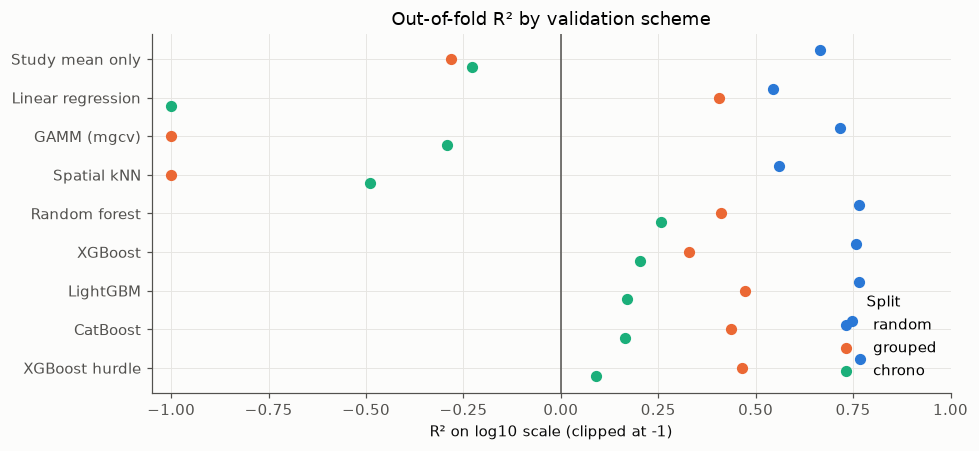

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.2))
names = list(MODELS)
rows = np.arange(len(names))
for offset, (scheme, color) in zip((-0.22, 0, 0.22), [("random", BLUE), ("grouped", ORANGE), ("chrono", AQUA)]):
    values = [results.loc[(n, scheme), "R2"] for n in names]
    ax.scatter(np.clip(values, -1, None), rows + offset, color=color, s=40, label=scheme, zorder=3)
ax.axvline(0, color=INK_MUTED, linewidth=1)
ax.set_yticks(rows, names)
ax.invert_yaxis()
ax.set(xlabel="R² on log10 scale (clipped at -1)", title="Out-of-fold R² by validation scheme", xlim=(-1.05, 1))
ax.legend(title="Split", loc="lower right")
fig.tight_layout()

The grouped R² above is pooled: all out-of-fold predictions scored together. Per-fold R² is shown below.
Each fold holds out different studies, and each fold's R² uses its own variance as the denominator, so
the fold mean is not the same quantity as the pooled score. Pooled R² is the headline. The per-fold
spread shows how much it depends on which studies are held out.

In [14]:
pd.DataFrame(
    {name: [score(predictions[name, "grouped"].iloc[t])["R2"] for _, t in SPLITS["grouped"]] for name in MODELS},
    index=[f"fold {i + 1}" for i in range(5)],
).T.assign(**{"fold mean": lambda t: t.mean(axis=1), "pooled": results.xs("grouped", level="scheme").R2})

,fold 1,fold 2,fold 3,fold 4,fold 5,fold mean,pooled
Study mean only,-5.197,-1.899,-0.949,-0.568,-0.109,-1.745,-0.283
Linear regression,-0.431,-0.909,0.253,-0.023,-0.244,-0.271,0.407
GAMM (mgcv),-16.422,-11.015,-0.607,-0.182,-0.176,-5.680,-1.099
Spatial kNN,-30.378,-7.398,-1.106,-0.971,-0.947,-8.160,-1.946
Random forest,-0.282,0.064,0.149,-0.649,0.196,-0.104,0.410
XGBoost,-0.391,0.051,-0.069,-0.854,0.295,-0.194,0.328
LightGBM,-0.556,0.004,0.302,-0.438,0.332,-0.071,0.473
CatBoost,-0.226,-0.122,0.103,-0.146,0.225,-0.033,0.438
XGBoost hurdle,-0.413,-0.130,0.300,-0.412,0.210,-0.089,0.464


Chronological holdout, split by whether the test row's study also has samples before 2015.

In [15]:
seen_study = df.study.isin(df.loc[df.year < CUTOFF, "study"])
pd.DataFrame({
    name: {
        (group, metric): score(predictions[name, "chrono"].where(mask))[metric]
        for group, mask in [("seen study", seen_study), ("unseen study", ~seen_study)]
        for metric in ("R2", "MAE")
    }
    for name in MODELS
}).T

seen study        unseen study       
                          R2    MAE           R2    MAE
Study mean only        0.215  1.243       -0.958  2.046
Linear regression      0.234  1.204       -4.665  2.990
GAMM (mgcv)            0.247  1.274       -1.169  1.837
Spatial kNN           -0.263  1.837       -0.904  1.808
Random forest          0.322  1.192        0.124  1.166
XGBoost                0.317  1.203       -0.007  1.321
LightGBM               0.296  1.222       -0.061  1.330
CatBoost               0.339  1.192       -0.137  1.265
XGBoost hurdle         0.300  1.184       -0.267  1.378

What the comparison shows:

- **Random folds score far higher than new studies.** The tree ensembles reach R² 0.75 to 0.77 on random
  folds and 0.30 to 0.44 on unseen studies. "Study mean only", which knows nothing but the study label,
  gets 0.67 on random folds. Part of the gap is the model recognising studies it has seen. Part is that a
  new study can differ in ways no feature records. The gap alone cannot separate the two.
- **On unseen studies, pooled R² is 0.47 for LightGBM**, 0.46 for the hurdle model, 0.44 for CatBoost,
  0.41 for random forest and linear regression and 0.33 for XGBoost. Much of this comes from telling
  sampling families apart: bulk water samples sit about four orders of magnitude above surface nets.
  Per fold the picture is weaker. A fold's R² compares against that fold's own mean, which no model could
  know in advance, and no model has a fold mean above zero. The closest are CatBoost (-0.03) and LightGBM
  (-0.07). About two thirds of tree predictions on new studies land within one order of magnitude,
  against 85 to 88% on random folds.
- **On the chronological holdout, the trees reach R² 0.09 to 0.26.** On rows from studies that also
  sampled before 2015 they reach 0.30 to 0.34. On studies that start in 2015 or later only random forest
  stays above zero (0.12).
- **Linear regression and the GAMM fail for specific reasons.** Before 2015 the only bulk-water study is
  Barrows et al., with one filter size (0.45 µm), so the bulk-water flag and mesh size are collinear.
  Linear regression fits large offsetting coefficients that explode on the chronological holdout, where
  new bulk-water studies use other meshes. It does well on grouped folds, where both are seen in
  training. The GAMM puts each study's level into its random intercept. Each study uses one protocol, so
  protocol effects can only be estimated from the little variation inside studies, and for an unseen
  study the GAMM predicts an average study at that location. That misses the very low SEA neuston
  studies in folds 1 and 2 badly. This says these two fits are unstable on this data. It does not show
  that linear or additive models are worse in general.
- **Spatial kNN** does worst on new studies (R² -1.95), below even the global mean. Its nearest
  neighbours belong to other studies with other protocols. When the SEA studies are held out, the
  nearest samples come from studies that report higher counts.

## 5. Which features carry information that transfers?

CatBoost is refit with different feature sets under random and grouped CV. Location and time only,
sampling protocol only, all features, all features with the sampling family in place of the raw method
name, and all features plus the study ID as a categorical feature. Adding the study ID can only help when
the test study was seen in training.

In [16]:
LOCATION_TIME = ["lat", "lon", "year", "month_sin", "month_cos"]
PROTOCOL = ["log_mesh", "log_depth", "method_family", "method"]
ABLATIONS = {
    "location and time only": LOCATION_TIME,
    "sampling protocol only": PROTOCOL,
    "all features": CATBOOST_FEATURES,
    "all features, family not raw method": FEATURES,
    "all features + study ID": CATBOOST_FEATURES + ["study"],
}
pd.DataFrame({
    (name, scheme): score(out_of_fold(lambda t, f=features: fit_catboost(t, f), SPLITS[scheme]))
    for name, features in ABLATIONS.items()
    for scheme in ("random", "grouped")
}).T[SHOWN].unstack()

R2            MAE        study MAE  \
                                    grouped random grouped random   grouped   
all features                          0.438  0.748   1.067  0.627     1.061   
all features + study ID               0.455  0.748   1.060  0.626     0.966   
all features, family not raw method   0.437  0.750   1.074  0.624     1.103   
location and time only               -0.139  0.716   1.606  0.686     1.497   
sampling protocol only                0.401  0.655   1.091  0.799     1.269   

                                           within 1 log         
                                    random      grouped random  
all features                         0.626        0.613  0.849  
all features + study ID              0.600        0.616  0.850  
all features, family not raw method  0.616        0.611  0.850  
location and time only               0.716        0.411  0.819  
sampling protocol only               0.736        0.654  0.784

Most of what transfers to new studies comes from the sampling protocol. Protocol features alone reach a
grouped R² of 0.40, and all features together reach 0.44. Location and time alone reach 0.72 on random
folds but fall below zero on new studies. On random folds, coordinates and dates pick out the cruise a
sample came from, which is also why adding the study ID changes nothing there: the model can already
tell. Grouping the 17 raw methods into three families loses nothing.

### 5.1 Do environmental covariates transfer to new studies?

Latitude, longitude and date pick out the cruise on random folds but fall below zero on new studies.
Raw coordinates say where a sample was taken, not why that place has plastic. This section tests
covariates that describe the place instead. If they carry signal that transfers between studies, adding
them should raise the grouped score. Each covariate is computed from the sample's location and month
only, never from the target or the study:

- Distance to the nearest coast, from the Natural Earth 10 m coastline with points added every 2 km.
- Distance to the nearest large river mouth. The river outlets come from Meijer et al. (2021), who
  model the floating plastic each of 31,819 outlets emits in tonnes per year. "Large" means the 1,000
  outlets with the highest emission, the number in the paper's title.
- River plastic input, the summed modelled emission of all outlets within 200 km.
- Population within 200 km, summed over the Natural Earth populated places. These are present-day
  populations, so the feature describes the place, not the year.
- Sea surface temperature for the sample's calendar month, from the NOAA OISST 1991-2020 climatology.
- Mean near-surface current speed from the Global Drifter Program climatology, averaged to 1°. Samples
  in cells without drifter data take the nearest cell that has it.

Distances are great-circle distances from a haversine ball tree, so they are correct across the
antimeridian. The 200 km radii and the 1,000-outlet cut were fixed before any model was run. The files
are in `data/environment` and `fetch_environment.py` downloads them. `README.md` lists the sources.

In [17]:
ENV_DATA = Path("data/environment")
EARTH_KM = 6371.0


def great_circle_tree(points: pd.DataFrame) -> BallTree:
    return BallTree(np.radians(points[["lat", "lon"]].to_numpy()), metric="haversine")


def coast_points(step_km: float = 2.0) -> pd.DataFrame:
    """Natural Earth coastline vertices, with points added along each segment so no gap exceeds step_km.
    The distance to the nearest point is then within step_km / 2 of the distance to the line."""
    points = []
    for shape in shapefile.Reader(ENV_DATA / "ne_10m_coastline.zip").shapes():
        for line in np.split(np.array(shape.points), shape.parts[1:]):
            lon, lat = np.radians(line).T
            gap = 2 * EARTH_KM * np.arcsin(np.sqrt(
                np.sin(np.diff(lat) / 2) ** 2 + np.cos(lat[:-1]) * np.cos(lat[1:]) * np.sin(np.diff(lon) / 2) ** 2
            ))
            steps = np.maximum(np.ceil(gap / step_km), 1).astype(int)
            segment = np.repeat(np.arange(len(gap)), steps)
            fraction = (np.arange(steps.sum()) - np.repeat(np.cumsum(steps) - steps, steps)) / np.repeat(steps, steps)
            points += [line[segment] + (line[segment + 1] - line[segment]) * fraction[:, None], line[-1:]]
    return pd.DataFrame(np.concatenate(points), columns=["lon", "lat"])


def shapefile_points(path: Path) -> pd.DataFrame:
    reader = shapefile.Reader(path)
    return pd.DataFrame([
        record.as_dict() | {"lon": shape.points[0][0], "lat": shape.points[0][1]}
        for record, shape in zip(reader.records(), reader.shapes())
    ])


def nearest_km(points: pd.DataFrame, at: pd.DataFrame) -> np.ndarray:
    return great_circle_tree(points).query(np.radians(at[["lat", "lon"]].to_numpy()))[0][:, 0] * EARTH_KM


def sum_within(points: pd.DataFrame, weight: str, at: pd.DataFrame, radius_km: float) -> np.ndarray:
    within = great_circle_tree(points).query_radius(np.radians(at[["lat", "lon"]].to_numpy()), radius_km / EARTH_KM)
    values = points[weight].to_numpy()
    return np.array([values[i].sum() for i in within])


coast = coast_points()
outlets = shapefile_points(ENV_DATA / "Meijer2021_midpoint_emissions.zip").rename(columns={"dots_exten": "tonnes"})
large_outlets = outlets.nlargest(1000, "tonnes")
places = shapefile_points(ENV_DATA / "ne_10m_populated_places_simple.zip")
currents = pd.read_csv(ENV_DATA / "drifter_currents_1deg.csv").assign(speed=lambda c: np.hypot(c.u, c.v))
with h5py.File(ENV_DATA / "sst.ltm.1991-2020.nc") as f:
    sst = f["sst"][:]  # month, latitude from 89.5 down to -89.5, longitude from 0.5 to 359.5


def environment(frame: pd.DataFrame) -> pd.DataFrame:
    """Environmental covariates for each row of frame, from its lat, lon and date."""
    current_cell = great_circle_tree(currents).query(np.radians(frame[["lat", "lon"]].to_numpy()))[1][:, 0]
    return pd.DataFrame({
        "coast_km": nearest_km(coast, frame),
        "river_mouth_km": nearest_km(large_outlets, frame),
        "river_input_200km": sum_within(outlets, "tonnes", frame, 200),
        "population_200km": sum_within(places, "pop_max", frame, 200),
        "sst_climatology": sst[
            frame.date.dt.month - 1,
            np.clip(np.floor(90 - frame.lat), 0, 179).astype(int),
            np.floor(frame.lon % 360).astype(int) % 360,
        ],
        "current_speed": currents.speed.to_numpy()[current_cell],
    }, index=frame.index)


env = environment(df)
ENV = list(env.columns)
df = df.join(env)
print(f"{len(coast):,} coastline points, {len(outlets):,} river outlets ({large_outlets.tonnes.sum() / outlets.tonnes.sum():.0%} "
      f"of modelled emission in the largest 1,000), {len(places):,} populated places, {len(currents):,} current cells")

666,756 coastline points, 31,819 river outlets (72% of modelled emission in the largest 1,000), 7,342 populated places, 33,948 current cells


Sanity checks on known points. Point Nemo, the ocean point farthest from land, is about 2,688 km from
the nearest coast. A sample in Honolulu harbour should be close to zero. The Fiji points sit on either
side of the antimeridian and should both be near the coast. The last two rows are the water samples
farthest from and closest to the coast.

In [18]:
known = pd.DataFrame({
    "lat": [-48.877, 21.307, -16.75, -16.75],
    "lon": [-123.393, -157.867, 179.99, -179.99],
    "date": pd.Timestamp("2015-01-15"),
}, index=["Point Nemo", "Honolulu harbour", "Fiji, 179.99° E", "Fiji, 179.99° W"])
extremes = df.loc[[df.coast_km.idxmax(), df.coast_km.idxmin()], ["lat", "lon", "date"]].set_axis(["farthest sample", "closest sample"])
checks = pd.concat([known, extremes])
display(checks.join(environment(checks)))
df[ENV].describe(percentiles=[0.1, 0.5, 0.9]).T

,lat,lon,date,coast_km,river_mouth_km,river_input_200km,population_200km,sst_climatology,current_speed
Point Nemo,-48.877,-123.393,2015-01-15 00:00:00,2692.280,5281.345,0.000,0,10.358,0.061
Honolulu harbour,21.307,-157.867,2015-01-15 00:00:00,1.692,6770.443,0.000,1028450,24.416,0.122
"Fiji, 179.99° E",-16.750,179.990,2015-01-15 00:00:00,3.185,3751.233,83.350,24187,28.901,0.021
"Fiji, 179.99° W",-16.750,-179.990,2015-01-15 00:00:00,1.623,3753.306,82.888,24187,28.812,0.049
farthest sample,-51.798,-138.930,2018-03-24 05:00:00,2452.776,6247.106,0.000,0,9.355,0.235
closest sample,58.521,5.704,2022-06-08 05:00:00,0.015,2117.961,0.000,355094,12.256,0.201


,count,mean,std,min,10%,50%,90%,max
coast_km,16988.0,3.795e+02,5.098e+02,1.485e-02,2.263,115.580,1.289e+03,2.453e+03
river_mouth_km,16988.0,2.376e+03,2.079e+03,4.527e-02,242.729,1731.391,5.899e+03,7.055e+03
river_input_200km,16988.0,4.943e+02,3.548e+03,0.000e+00,0.000,0.000,5.748e+02,1.602e+05
population_200km,16988.0,1.634e+06,4.067e+06,0.000e+00,0.000,308.500,5.588e+06,4.797e+07
sst_climatology,16988.0,2.173e+01,6.409e+00,-1.790e+00,11.971,23.631,2.793e+01,3.000e+01
current_speed,16988.0,1.210e-01,1.640e-01,6.325e-04,0.014,0.064,2.973e-01,1.165e+00


Each feature set is scored with CatBoost and LightGBM, using the settings from section 4. CatBoost also
gets the raw method name whenever the sampling family is in the set, as in section 5, so its rows for
current features, protocol only and location and time only repeat section 5. Protocol here means mesh,
depth and sampling family. Fold mean R² is the per-fold mean from section 4.

In [19]:
PROTOCOL_FAMILY = ["log_mesh", "log_depth", "method_family"]
FEATURE_SETS = {
    "current features": FEATURES,
    "current + environmental": FEATURES + ENV,
    "protocol only": PROTOCOL_FAMILY,
    "protocol + environmental": PROTOCOL_FAMILY + ENV,
    "location and time only": LOCATION_TIME,
    "environmental only": ENV,
}


def env_models(features: list[str]) -> dict[str, Model]:
    catboost_features = features + ["method"] if "method_family" in features else features
    return {
        "CatBoost": lambda train: fit_catboost(train, catboost_features),
        "LightGBM": sklearn_model(LGBMRegressor(**BOOSTER_DEFAULTS, verbose=-1), features),
    }


def grouped_scores(pred: pd.Series, folds: Folds) -> dict[str, float]:
    return {
        "pooled R2": score(pred)["R2"],
        "fold mean R2": np.mean([score(pred.iloc[test])["R2"] for _, test in folds]),
        "within 1 log": score(pred)["within 1 log"],
    }


def compare(sets: list[str], folds: Folds) -> pd.DataFrame:
    return pd.DataFrame({
        (model, name): grouped_scores(out_of_fold(fit, folds), folds)
        for name in sets
        for model, fit in env_models(FEATURE_SETS[name]).items()
    }).T


compare(list(FEATURE_SETS), SPLITS["grouped"])

,,pooled R2,fold mean R2,within 1 log
CatBoost,current features,0.438,-0.033,0.613
LightGBM,current features,0.473,-0.071,0.639
CatBoost,current + environmental,0.476,-0.010,0.617
LightGBM,current + environmental,0.506,-0.019,0.656
CatBoost,protocol only,0.401,0.025,0.654
LightGBM,protocol only,0.497,0.120,0.752
CatBoost,protocol + environmental,0.449,-0.090,0.569
LightGBM,protocol + environmental,0.466,-0.062,0.608
CatBoost,location and time only,-0.139,-1.422,0.411
LightGBM,location and time only,-0.097,-1.128,0.492


The same feature sets on the chronological holdout, split by seen and unseen studies as in section 4.

In [20]:
pd.DataFrame({
    (model, name): {
        (group, metric): score(pred.where(mask))[metric]
        for group, mask in [("all", df.year >= CUTOFF), ("seen study", seen_study), ("unseen study", ~seen_study)]
        for metric in ("R2", "within 1 log")
    }
    for name, features in FEATURE_SETS.items()
    for model, fit in env_models(features).items()
    for pred in [out_of_fold(fit, SPLITS["chrono"])]
}).T

all              seen study               \
                                      R2 within 1 log         R2 within 1 log   
CatBoost current features          0.165        0.626      0.339        0.643   
LightGBM current features          0.170        0.585      0.296        0.625   
CatBoost current + environmental   0.171        0.599      0.346        0.639   
LightGBM current + environmental   0.196        0.583      0.293        0.639   
CatBoost protocol only             0.011        0.458      0.223        0.650   
LightGBM protocol only             0.078        0.504      0.269        0.729   
CatBoost protocol + environmental  0.188        0.592      0.303        0.642   
LightGBM protocol + environmental  0.170        0.575      0.277        0.679   
CatBoost location and time only   -0.848        0.362     -0.337        0.424   
LightGBM location and time only   -0.880        0.344     -0.366        0.432   
CatBoost environmental only       -0.276        0.397     -0.068        0.448   
LightGBM environmental only       -0.279        0.411     -0.088        0.472   

                                  unseen study               
                                            R2 within 1 log  
CatBoost current features               -0.137        0.611  
LightGBM current features               -0.061        0.551  
CatBoost current + environmental        -0.133        0.564  
LightGBM current + environmental         0.011        0.534  
CatBoost protocol only                  -0.358        0.292  
LightGBM protocol only                  -0.255        0.308  
CatBoost protocol + environmental       -0.027        0.548  
LightGBM protocol + environmental       -0.032        0.484  
CatBoost location and time only         -1.711        0.309  
LightGBM location and time only         -1.749        0.268  
CatBoost environmental only             -0.653        0.352  
LightGBM environmental only             -0.630        0.359

Surface nets only. All three sampling families differ by orders of magnitude, so on the full data any
spatial signal has to compete with the method effect. Restricting to surface nets and regrouping their
studies into five folds isolates how well location and environment predict between net studies.

In [21]:
nets = np.flatnonzero(df.method_family == "surface net")
NET_FOLDS = [(nets[train], nets[test]) for train, test in GroupKFold(5).split(nets, groups=df.study.iloc[nets])]
print(f"{len(nets):,} surface net samples from {df.study.iloc[nets].nunique()} studies")
compare(["location and time only", "environmental only", "current features", "current + environmental"], NET_FOLDS)

14,233 surface net samples from 58 studies


,,pooled R2,fold mean R2,within 1 log
CatBoost,location and time only,0.141,-0.470,0.650
LightGBM,location and time only,0.123,-0.525,0.695
CatBoost,environmental only,-0.381,-1.390,0.520
LightGBM,environmental only,-0.343,-1.296,0.537
CatBoost,current features,0.351,-0.039,0.727
LightGBM,current features,0.254,-0.168,0.719
CatBoost,current + environmental,0.361,-0.064,0.725
LightGBM,current + environmental,0.335,-0.058,0.719


Section 4 showed that the grouped score depends on which studies land in which fold. To see whether the
difference between current and current + environmental is larger than that, the comparison is repeated
over 10 random assignments of studies to five folds. Both feature sets get the same folds in each
repeat, so the gain is a paired difference.

In [22]:
REPEATS = 10
repeated = pd.DataFrame([
    {"repeat": r, "model": model, "features": name, "pooled R2": score(out_of_fold(fit, folds))["R2"]}
    for r in range(REPEATS)
    for folds in [list(GroupKFold(5, shuffle=True, random_state=r).split(df, groups=df.study))]
    for name in ["current features", "current + environmental"]
    for model, fit in env_models(FEATURE_SETS[name]).items()
]).pivot(index=["model", "repeat"], columns="features", values="pooled R2")
gain = repeated["current + environmental"] - repeated["current features"]
summary = pd.concat({
    "current features": repeated["current features"].groupby("model").agg(["mean", "min", "max"]),
    "current + environmental": repeated["current + environmental"].groupby("model").agg(["mean", "min", "max"]),
    "gain": gain.groupby("model").agg(["mean", "min", "max"]),
}, axis=1)
summary["environmental wins"] = (gain > 0).groupby("model").sum().astype(str) + f" of {REPEATS}"
summary

current features               current + environmental                \
                     mean    min    max                    mean    min    max   
model                                                                           
CatBoost            0.481  0.415  0.548                   0.457  0.393  0.525   
LightGBM            0.454  0.382  0.525                   0.449  0.326  0.558   

           gain               environmental wins  
           mean    min    max                     
model                                             
CatBoost -0.024 -0.070  0.019            3 of 10  
LightGBM -0.005 -0.112  0.049            5 of 10

On the original folds the environmental covariates look like a small win. Adding them raises pooled
grouped R² from 0.44 to 0.48 for CatBoost and from 0.47 to 0.51 for LightGBM, and lifts the fold means
a little, though both stay below zero. The repeated folds show that this gain is fold-assignment noise.
Over 10 random assignments of studies, CatBoost averages 0.48 without them and 0.46 with them, and
wins in 3 of 10 repeats. LightGBM averages 0.45 and 0.45 and wins in 5 of 10. The paired gain ranges
from -0.07 to +0.02 for CatBoost and from -0.11 to +0.05 for LightGBM, while the baseline alone moves
between 0.38 and 0.55 depending on the folds. The difference is smaller than the noise and not
consistently positive.

The other tests point the same way:

- Environmental features alone score -0.97 and -1.06 on new studies, worse than latitude, longitude and
  date alone (-0.14 and -0.10). Six continuous descriptors of a place identify it about as precisely
  as its coordinates do, so the trees use them to recognise a study's region, and that fails on a new
  study.
- Within surface nets, location and time transfer a little (0.14 and 0.12) and environment alone does
  not (-0.38 and -0.34). Adding environment to the current features changes CatBoost from 0.35 to 0.36
  and LightGBM from 0.25 to 0.34. That is one fold assignment, and the full-data repeats show swings of
  this size from fold assignment alone.
- On the chronological holdout, adding environment to the current features changes R² on unseen
  studies from -0.14 to -0.13 for CatBoost and from -0.06 to 0.01 for LightGBM, while the share within
  one order of magnitude falls by 2 to 5 points. Protocol plus environment does much better than protocol
  only on unseen studies (-0.03 against -0.36 for CatBoost), but it lands at about the level of the
  current features, so here environment replaces location and time rather than adding to them.
- LightGBM with protocol features only scores 0.50 on the original folds, above its 0.47 with all
  current features. Location and time cost LightGBM accuracy on new studies, which fits the same
  picture.

So these covariates do not transfer to unseen studies any better than raw coordinates, and any gain
is within fold-assignment noise. This is a result about these covariates in this form: static
population, modelled river emission, 1° climatologies and a 200 km radius chosen in advance. With 72
studies, mostly one protocol in one region each, the data has little room to separate the effect of a
place from the effect of the study that sampled it.

## 6. Genetic algorithm hyperparameter search

CatBoost is tuned because it has the best grouped-CV score. The search only sees data from before 2015
and scores candidates with 4-fold grouped CV on those years. The tuned parameters are then scored on the
2015-onwards holdout. That holdout is not a pristine test set: section 4 already looked at it, and the
choice of CatBoost used grouped CV over all years. Treat the holdout numbers as exploratory.

Each individual is a vector of genes in [0, 1], decoded into CatBoost parameters below. Fitness is the
RMSE of the pooled out-of-fold predictions, so every sample counts equally, matching how the other
scores are reported. Each generation keeps the two best individuals unchanged
(elitism) and fills the rest with children: parents are picked by 3-way tournament, genes are blended
with random weights, and each gene mutates with probability 0.2. A random search with the same number of
evaluations is the control. Without it, there is no evidence that the GA adds anything.

In [23]:
SPACE = {  # name: (low, high, scale)
    "depth": (3, 8, "int"),
    "learning_rate": (0.01, 0.3, "log"),
    "iterations": (200, 1000, "int"),
    "l2_leaf_reg": (0.1, 30, "log"),
    "random_strength": (0.1, 10, "log"),
    "subsample": (0.5, 1.0, "linear"),
    "rsm": (0.5, 1.0, "linear"),
}
dev = df[df.year < CUTOFF]
holdout = df[df.year >= CUTOFF]
DEV_FOLDS = list(GroupKFold(4).split(dev, groups=dev.study))


def decode(genes: np.ndarray) -> dict[str, float | int | str]:
    params: dict[str, float | int | str] = {"bootstrap_type": "Bernoulli"}
    for gene, (name, (low, high, scale)) in zip(genes, SPACE.items()):
        if scale == "log":
            params[name] = float(low * (high / low) ** gene)
        else:
            value = low + gene * (high - low)
            params[name] = round(value) if scale == "int" else float(value)
    return params


def cv_rmse(params: dict) -> float:
    pred = np.empty(len(dev))
    for train_idx, test_idx in DEV_FOLDS:
        pred[test_idx] = fit_catboost(dev.iloc[train_idx], **params)(dev.iloc[test_idx])
    return float(np.sqrt(np.mean((pred - dev.y.to_numpy()) ** 2)))


def evaluated(genes: np.ndarray, generation: int) -> dict:
    params = decode(genes)
    return {"generation": generation, "genes": genes.tolist(), "params": params, "rmse": cv_rmse(params)}


def tournament(population: np.ndarray, fitness: np.ndarray, rng: np.random.Generator, k: int = 3) -> np.ndarray:
    contenders = rng.choice(len(population), k, replace=False)
    return population[contenders[np.argmin(fitness[contenders])]]


def genetic_search(rng: np.random.Generator, size: int = 12, generations: int = 10, elite: int = 2,
                   mutation: float = 0.2) -> list[dict]:
    history = [evaluated(g, 0) for g in rng.random((size, len(SPACE)))]
    population = np.array([h["genes"] for h in history])
    fitness = np.array([h["rmse"] for h in history])
    for generation in range(1, generations):
        keep = np.argsort(fitness)[:elite]
        children, child_fitness = list(population[keep]), list(fitness[keep])
        while len(children) < size:
            a, b = tournament(population, fitness, rng), tournament(population, fitness, rng)
            weights = rng.random(len(SPACE))
            child = weights * a + (1 - weights) * b
            child += (rng.random(len(SPACE)) < mutation) * rng.normal(0, 0.15, len(SPACE))
            history.append(evaluated(np.clip(child, 0, 1), generation))
            children.append(np.array(history[-1]["genes"]))
            child_fitness.append(history[-1]["rmse"])
        population, fitness = np.array(children), np.array(child_fitness)
    return history


def random_search(rng: np.random.Generator, evaluations: int) -> list[dict]:
    return [evaluated(rng.random(len(SPACE)), 0) for _ in range(evaluations)]


GA_SETTINGS = dict(size=12, generations=10, elite=2, mutation=0.2)
SEARCH_CONFIG = json.loads(json.dumps({
    "space": SPACE, "ga": GA_SETTINGS, "seed": SEED, "dev_data": str(pd.util.hash_pandas_object(dev[CATBOOST_FEATURES + ["y", "study"]]).sum()),
}))


def cached(path: Path, compute: Callable[[], list[dict]]) -> list[dict]:
    """Runs a slow search once and reuses the saved result for as long as SEARCH_CONFIG is unchanged."""
    if path.exists() and (saved := json.loads(path.read_text()))["config"] == SEARCH_CONFIG:
        return saved["history"]
    history = compute()
    path.write_text(json.dumps({"config": SEARCH_CONFIG, "history": history}, indent=1))
    return history


ga_history = cached(ARTIFACTS / "ga_search.json", lambda: genetic_search(np.random.default_rng(SEED), **GA_SETTINGS))
rs_history = cached(ARTIFACTS / "random_search.json",
                    lambda: random_search(np.random.default_rng(SEED + 1), len(ga_history)))
default_rmse = cv_rmse({})
print(f"{len(ga_history)} evaluations per search. Default CatBoost dev RMSE: {default_rmse:.3f}")

102 evaluations per search. Default CatBoost dev RMSE: 1.491


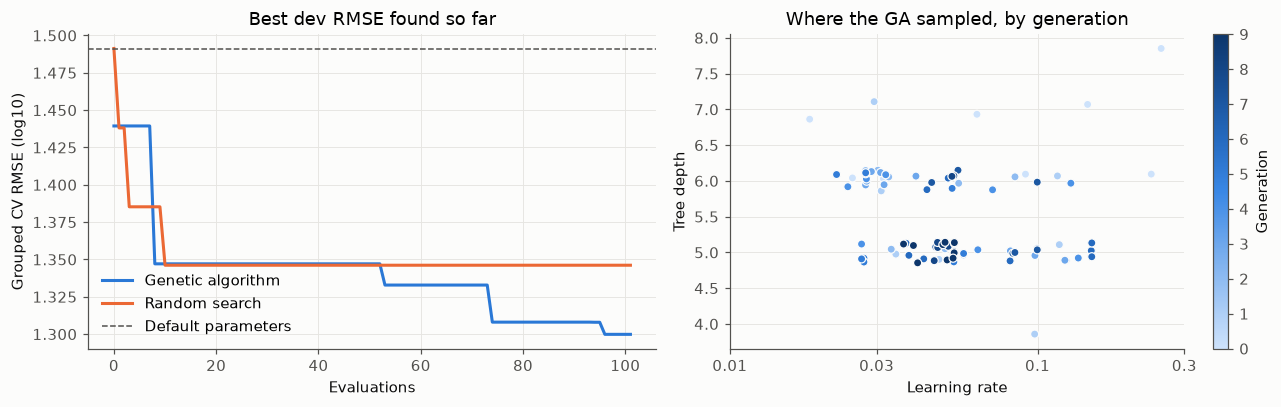

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for history, label, color in [(ga_history, "Genetic algorithm", BLUE), (rs_history, "Random search", ORANGE)]:
    axes[0].plot(np.minimum.accumulate([h["rmse"] for h in history]), color=color, label=label)
axes[0].axhline(default_rmse, color=INK_MUTED, linewidth=1, linestyle="--", label="Default parameters")
axes[0].set(title="Best dev RMSE found so far", xlabel="Evaluations", ylabel="Grouped CV RMSE (log10)")
axes[0].legend()

ga_frame = pd.DataFrame([h["params"] | {"generation": h["generation"], "rmse": h["rmse"]} for h in ga_history])
points = axes[1].scatter(ga_frame.learning_rate, ga_frame.depth + np.random.default_rng(0).uniform(-0.15, 0.15, len(ga_frame)),
                         c=ga_frame.generation, cmap=SEQUENTIAL, s=28, edgecolor="#fcfcfb", linewidth=0.8)
fig.colorbar(points, ax=axes[1], label="Generation")
axes[1].set(xscale="log", title="Where the GA sampled, by generation", xlabel="Learning rate", ylabel="Tree depth")
axes[1].set_xticks([0.01, 0.03, 0.1, 0.3], ["0.01", "0.03", "0.1", "0.3"], minor=False)
axes[1].set_xticks([], minor=True)
fig.tight_layout()

In [25]:
def best(history: list[dict]) -> dict:
    return min(history, key=lambda h: h["rmse"])


candidates = {
    "Default": {"params": {}, "rmse": default_rmse},
    "Random search": best(rs_history),
    "Genetic algorithm": best(ga_history),
}
chosen = min(candidates, key=lambda name: candidates[name]["rmse"])
print(f"Lowest dev RMSE: {chosen}. Its parameters are used for the final model.")
display(pd.DataFrame({name: c["params"] for name, c in candidates.items()}).T.drop(columns="bootstrap_type"))
pd.DataFrame({
    name: {"dev CV RMSE": c["rmse"]} | metrics(holdout.y.to_numpy(), fit_catboost(dev, **c["params"])(holdout))
    for name, c in candidates.items()
}).T[["dev CV RMSE", "R2", "MAE", "RMSE", "within 1 log"]]

Lowest dev RMSE: Genetic algorithm. Its parameters are used for the final model.


,depth,learning_rate,iterations,l2_leaf_reg,random_strength,subsample,rsm
Default,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random search,4,0.052,916,1.115,1.51,0.512,0.837
Genetic algorithm,5,0.051,327,0.122,7.5,0.614,0.545


,dev CV RMSE,R2,MAE,RMSE,within 1 log
Default,1.491,0.165,1.231,1.867,0.626
Random search,1.346,0.115,1.243,1.923,0.644
Genetic algorithm,1.300,0.160,1.197,1.873,0.645


The GA found a better development score than random search with the same 102 evaluations (RMSE 1.30
against 1.35, default 1.49), and its later generations settle on depth 5 with a learning rate around
0.05. That improvement does not reach the holdout. The default parameters score R² 0.17 there, the GA's
0.16 and random search's 0.12, and their shares within one order of magnitude differ by under two
points. This is one run with one seed, so it does not show the GA is better than random
search in general. Tuning cannot fix a gap that comes from the data: the model is limited by what
transfers between studies, not by its hyperparameters.

## 7. SHAP explanations

CatBoost with the parameters that scored best in development is refit on every water record and explained
with exact TreeSHAP values. Categorical features are shown as integer codes in the beeswarm. SHAP explains
what this fitted model does. It does not show that a feature causes higher concentrations.

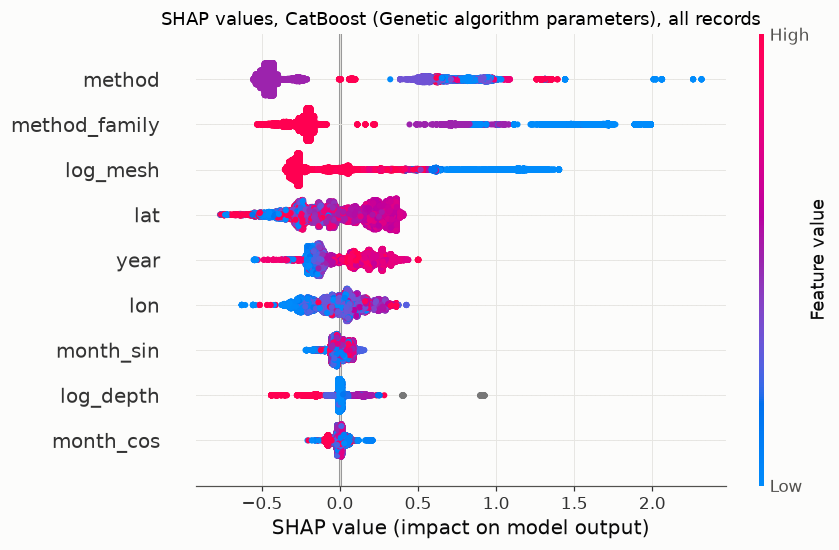

In [26]:
final = train_catboost(df, **candidates[chosen]["params"])
X = df[CATBOOST_FEATURES]
shap_values = shap.TreeExplainer(final)(X)
codes = X.assign(**{c: X[c].astype("category").cat.codes for c in ("method_family", "method")})
shap.summary_plot(shap_values.values, codes, max_display=10, show=False)
plt.title(f"SHAP values, CatBoost ({chosen} parameters), all records")
plt.tight_layout()

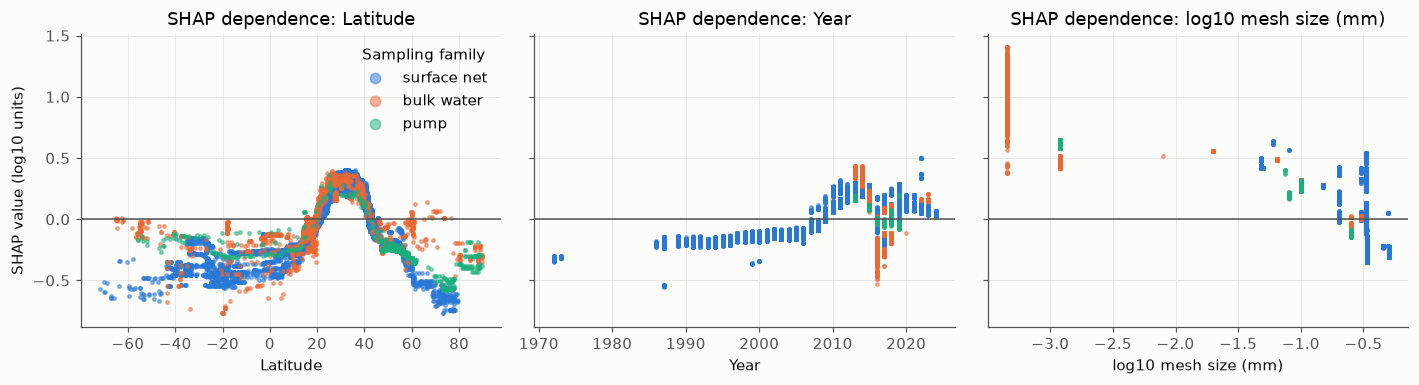

In [27]:
contributions = pd.DataFrame(shap_values.values, columns=CATBOOST_FEATURES, index=df.index)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, feature, label in zip(axes, ["lat", "year", "log_mesh"], ["Latitude", "Year", "log10 mesh size (mm)"]):
    for name, color in families.items():
        part = df.method_family == name
        ax.scatter(df.loc[part, feature], contributions.loc[part, feature], color=color, s=5, alpha=0.5, label=name)
    ax.axhline(0, color=INK_MUTED, linewidth=1)
    ax.set(xlabel=label, title=f"SHAP dependence: {label}")
axes[0].set_ylabel("SHAP value (log10 units)")
axes[0].legend(title="Sampling family", markerscale=3)
fig.tight_layout()

Sampling method, sampling family and mesh size carry the largest contributions, followed by latitude and
year. The latitude curve peaks between about 20° and 45° N, where the North Atlantic and North Pacific
subtropical gyres are. That is where floating plastic is known to accumulate, and also where the largest
studies sampled. The year curve is flat until about 2005 and then rises by roughly half an order of
magnitude. That is harder to read: Law et al. (2010), the largest study in this data, found no clear
trend in its own North Atlantic series, so the rise may come from newer studies using different methods
rather than from more plastic.

The finest meshes get the largest positive contributions, which matches the physics: finer filters catch
more small particles. Before the Barrows unit fix in section 1, the same plot showed the opposite. The
0.45 µm samples come from only two studies, though, so this curve is still mostly those studies.

The single highest prediction, broken down feature by feature:

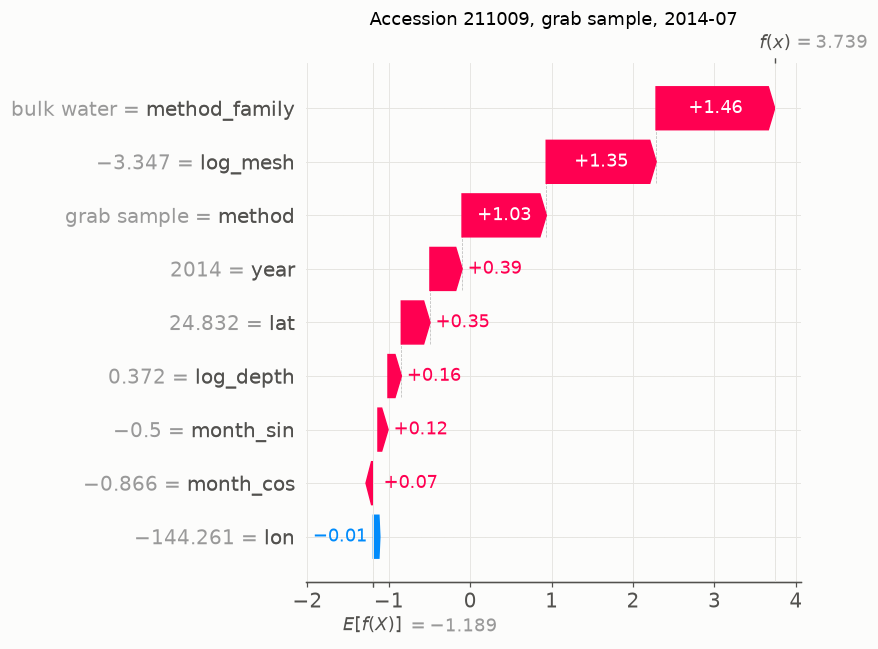

In [28]:
top = int(np.argmax(final.predict(X)))
shap.plots.waterfall(shap_values[top], show=False)
plt.title(f"Accession {df.accession[top]}, {df.method[top]}, {df.date[top]:%Y-%m}")
plt.tight_layout()
plt.show()

### 7.1 SHAP against the study offsets from the mixed model

The intercept-only mixed model from section 2.2 estimates one offset per study: how far that study sits
above or below the global mean. Below, each point is a study. The x axis is its offset. The y axis is the
average SHAP contribution of one feature group across that study's samples.

This is descriptive. It shows which inputs the fitted model routes study-level differences through. It
cannot separate geography from study recognition, because coordinates and dates can pick out a cruise
as easily as mesh size can, and a model fitted to these outcomes will track the study offsets by
construction. The grouped-CV ablations in section 5 are the test of what transfers to new studies.

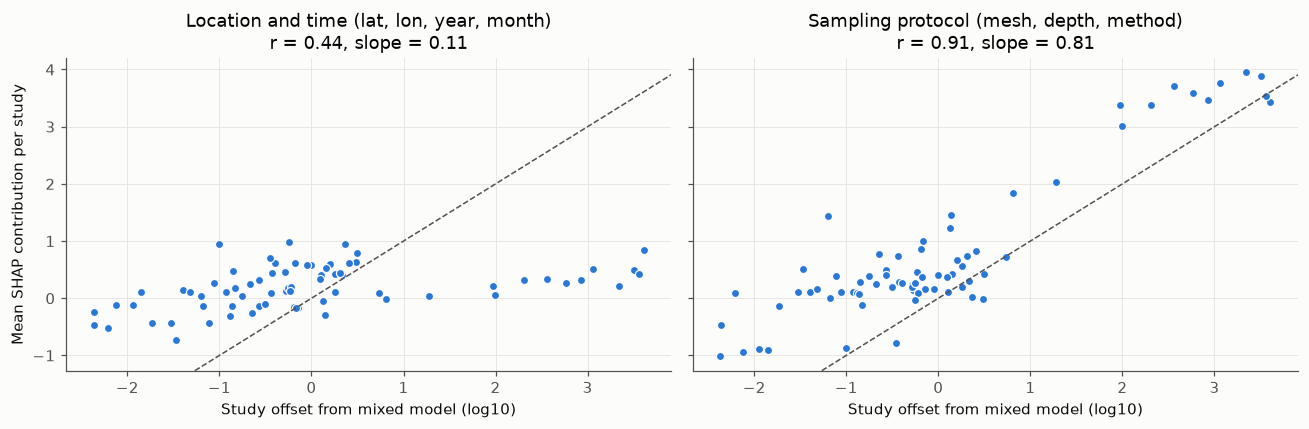

In [29]:
offsets = pd.Series({g: v.iloc[0] for g, v in null_mixed.random_effects.items()})
GROUPS = {
    "Location and time (lat, lon, year, month)": ["lat", "lon", "year", "month_sin", "month_cos"],
    "Sampling protocol (mesh, depth, method)": ["log_mesh", "log_depth", "method_family", "method"],
}
per_study = pd.DataFrame({name: contributions[cols].sum(axis=1) for name, cols in GROUPS.items()}).groupby(df.study).mean()
per_study["offset"] = offsets

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, name in zip(axes, GROUPS):
    slope = np.polyfit(per_study.offset, per_study[name], 1)[0]
    r = per_study.offset.corr(per_study[name])
    ax.scatter(per_study.offset, per_study[name], color=BLUE, s=28, edgecolor="#fcfcfb", linewidth=0.8)
    ax.axline((0, 0), slope=1, color=INK_MUTED, linewidth=1, linestyle="--")
    ax.set(title=f"{name}\nr = {r:.2f}, slope = {slope:.2f}", xlabel="Study offset from mixed model (log10)")
axes[0].set_ylabel("Mean SHAP contribution per study")
fig.tight_layout()
plt.show()

The highest prediction is a Barrows et al. grab sample from the North Pacific, at about 5,500 pieces/m3.
The bulk-water family, the 0.45 µm filter and the grab-sample method together add almost four orders of
magnitude. No other study used this method, so these contributions say "this is a Barrows sample" as
much as anything about grab samples.

Across studies, the sampling-protocol features follow the study offsets closely (r = 0.91, slope 0.81)
and absorb most of their size. Location and time follow them more loosely (r = 0.44) and with a much
smaller slope (0.11). So the fitted model routes most between-study differences through mesh size, depth
and method. As said above, this describes the model, it does not prove the protocol effects are
physical.

## 8. Predicted surface concentration map

This map is an exploratory model scenario, not a validated concentration map. The final model predicts
every 2° cell for one standard sample: a manta net with a 0.333 mm mesh at the surface in 2015. The
twelve monthly predictions are averaged on the log scale. Fixing the protocol inputs does not remove
confounding the model learned in training, and grouped CV showed weak transfer to new studies, so the
map should not be read as locating accumulation zones. Cells more than 500 km from any surface-net
observation are blanked, because the model has no comparable data there.

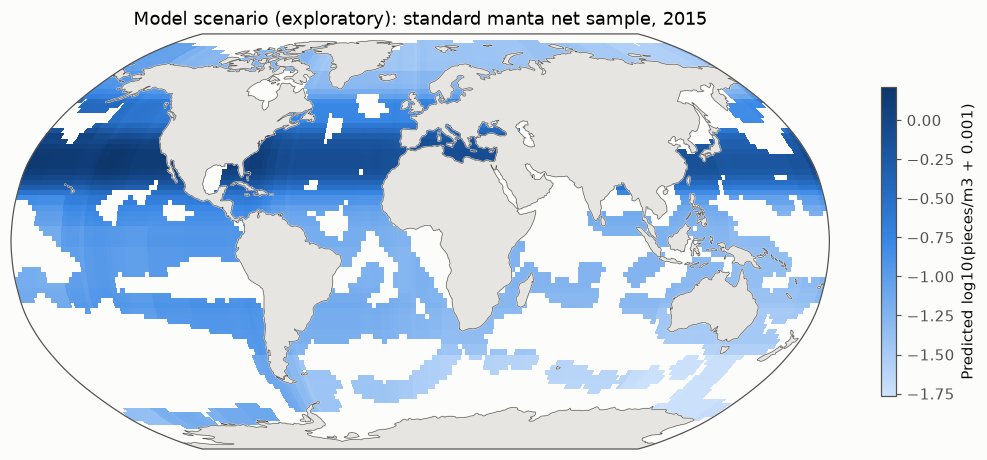

In [30]:
lat_centres, lon_centres = np.arange(-79, 90, 2.0), np.arange(-179, 180, 2.0)
lat_grid, lon_grid = np.meshgrid(lat_centres, lon_centres, indexing="ij")
cells = pd.DataFrame({"lat": lat_grid.ravel(), "lon": lon_grid.ravel()}).assign(
    year=2015, log_mesh=np.log10(0.333), log_depth=0.0, method_family="surface net", method="manta net"
)
monthly = [
    final.predict(cells.assign(month_sin=np.sin(2 * np.pi * m / 12), month_cos=np.cos(2 * np.pi * m / 12))[CATBOOST_FEATURES])
    for m in range(1, 13)
]
surface = np.mean(monthly, axis=0)
surface_nets = df[df.method_family == "surface net"]
distance_km = BallTree(np.radians(surface_nets[["lat", "lon"]]), metric="haversine").query(np.radians(cells[["lat", "lon"]]))[0][:, 0] * 6371
surface[distance_km > 500] = np.nan

fig = plt.figure(figsize=(12, 5.2))
ax = fig.add_subplot(projection=ccrs.Robinson())
ax.set_global()
mesh = ax.pcolormesh(np.arange(-180, 181, 2.0), np.arange(-80, 91, 2.0), surface.reshape(lat_grid.shape),
                     cmap=SEQUENTIAL, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, color="#e6e5e1", zorder=2)
ax.coastlines(linewidth=0.4, color=INK_MUTED, zorder=3)
fig.colorbar(mesh, ax=ax, shrink=0.7, label="Predicted log10(pieces/m3 + 0.001)")
ax.set_title("Model scenario (exploratory): standard manta net sample, 2015")
plt.show()

The horizontal banding comes from the trees splitting on latitude. The high band between 20° and 45° N
and the high Mediterranean values agree with published accumulation patterns, but those are also the
areas sampled most densely by the studies with the highest counts, so the map cannot tell the two apart.

## 9. Conclusions

1. **Random-split scores overstate how well the models handle new studies.** Tree ensembles reach
   R² 0.75 to 0.77 on random folds. With whole studies held out, the best models (LightGBM, the hurdle
   model and CatBoost) reach a pooled R² of 0.44 to 0.47, no model has a fold mean above zero, and on the
   2015-onwards holdout every model is between -1.7 and 0.26. The grouped score itself depends on the
   fold assignment: over 10 random assignments CatBoost and LightGBM move between 0.38 and 0.55
   (section 5.1). Study identity alone explains 63% of the
   target variance (ICC), and on random folds the study label adds nothing to location and date,
   because those already identify the cruise.
2. **What transfers is mostly the sampling protocol.** Protocol features alone reach a grouped R² of
   0.40, and adding location and time lifts it to 0.44. Location and time alone fall below zero on new
   studies. About two thirds of tree predictions on new studies are within one order of magnitude.
   Distance to coast and river mouths, river plastic input, population, sea surface temperature and
   current speed do not change this. Over 10 random fold assignments their gain averages below zero and
   stays between -0.11 and +0.05 (section 5.1).
3. **The ranking of models depends on the split.** On random folds the trees are level and the GAMM is
   close behind. On new studies LightGBM, the hurdle model, CatBoost, random forest and linear regression
   are close together, while the GAMM and spatial kNN fall below the global mean. Linear regression fails
   on the chronological holdout because the pre-2015 sampling fields are collinear.
4. **Tuning does not close the gap.** The genetic algorithm beat an equal-budget random search on the
   development folds (RMSE 1.30 against 1.35) and did not improve the holdout over default parameters.
5. **Data quality matters more than model choice here.** Two studies in the NCEI export are stored
   10^6 too low because of a unit conversion error. Before Barrows et al. was fixed, the best grouped R²
   was -0.05 and SHAP gave the finest meshes a negative effect.

The practical message for anyone publishing a model on aggregated microplastic data is to report grouped
validation. A random-split R² mostly measures recognition of studies the model has already seen.

### Changes from the synopsis

- The data is the current NCEI export (16,988 ocean-water records, 72 studies, samples to 2024), not the
  2023 data descriptor release. It adds 14 accessions.
- The target is `log10(conc + 0.001)`, not `log1p`, because `log1p` leaves 65% of the data almost
  untransformed (section 2.1).
- The modelling set is the ocean-water records only, not every record in pieces/m3. The 893 beach
  records in pieces/m3 measure sand.
- The Barrows et al. (2018) and Dehm et al. (2020) values are rescaled by 10^6 to fix a unit conversion
  error (section 1).
- Studies are grouped by publication and accession together, so neither a publication split across two
  accessions nor an accession holding two publications ends up on both sides of a split.
- Medium is not a feature, because only ocean water remains after filtering.
- The GAMM is fitted with R's `mgcv` (`gamm.R`): a spherical spline over latitude and longitude, a
  smooth of year, linear protocol terms and a random effect per study.
- Added beyond the synopsis: a study-mean reference, a spatial kNN baseline, LightGBM, an XGBoost hurdle
  model for the zeros, a random-search control for the GA, feature-group ablations, a seen/unseen
  breakdown of the chronological holdout, and a test of environmental covariates (section 5.1).

### Next steps

- The static environmental covariates in section 5.1 did not transfer. Fields that vary by year, such as
  sea surface temperature and wind at the sampling date, are untested.
- Use sampled water volume or tow length if they can be recovered from the source papers. Zeros from a
  short tow and zeros from a long one mean different things.
- Model the sediment (pieces/kg) and beach records separately, as the synopsis planned.